<a href="https://colab.research.google.com/github/gerardowarbringer-eng/Programacion-para-Analitica-Descrip-Predict/blob/main/Actividad_EDA_predictivo_bank_marketing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad: análisis exploratorio de datos para analítica predictiva
## Caso: suscripción a un depósito a plazo tras una llamada de telemarketing bancario

Programación para Analítica Descriptiva y Predictiva · Tema : EDA con Analítica Predictiva
Maestría en Inteligencia Artificial y Analítica de Datos · UACJ

**Nombre del estudiante:** GERARDO ISIDORO REYES

**Matrícula:** 271770

**Fecha:** 09/10/2026

## Propósito

Aplicar, de forma individual y sobre un conjunto de datos nuevo, el procedimiento de análisis exploratorio para analítica predictiva revisado en el notebook guiado del caso Telco. El producto de la actividad es una **hoja de decisiones** de preprocesamiento y modelado, sustentada en evidencia obtenida con el código.

No se entrena ningún modelo en esta actividad.

## Instrucciones de entrega

1. Completa las celdas de código y las de texto marcadas con **Tu predicción**, **Tu observación** o **Tu respuesta**.
2. Antes de entregar, ejecuta el notebook completo con *Kernel > Restart & Run All*. El notebook debe ejecutarse de principio a fin sin errores.
3. Guarda el archivo como `Apellido_Nombre_EDA_predictivo.ipynb` y entrégalo en el medio indicado por el profesor.
4. La actividad es individual. Las predicciones deben escribirse **antes** de ejecutar cada celda de código.

## Reglas de trabajo

- Usa solo el conjunto `df` y las librerías ya importadas.
- Después de la división de la parte C, el conjunto `prueba` **no se utiliza** en ninguna celda.
- Usa `random_state=42` en toda operación aleatoria, para que los resultados sean comparables.
- Las observaciones y las decisiones citan cifras obtenidas con tu propio código.

## Conjunto de datos y fuente

**Bank Marketing** (archivo `bank-additional-full.csv`), del repositorio UCI de aprendizaje automático. Cada fila es un contacto telefónico de una campaña de marketing directo de un banco portugués. El conjunto contiene 41,188 contactos ordenados por fecha, de mayo de 2008 a noviembre de 2010, y 21 columnas.


**Problema predictivo.** Clasificación binaria: dadas las características de un cliente y del contexto de la campaña, predecir si el cliente contratará el depósito a plazo (`y`).

**Diccionario de datos**

| Columna | Contenido |
| --- | --- |
| `age` | Edad del cliente |
| `job`, `marital`, `education` | Ocupación, estado civil y escolaridad |
| `default`, `housing`, `loan` | Si tiene crédito en incumplimiento, crédito hipotecario y préstamo personal |
| `contact` | Medio de contacto: `cellular` o `telephone` |
| `month`, `day_of_week` | Mes y día de la semana del último contacto de la campaña actual |
| `duration` | Duración de la última llamada, en segundos |
| `campaign` | Número de contactos con este cliente en la campaña actual, incluido el último |
| `pdays` | Días transcurridos desde el último contacto de una campaña anterior; `999` indica que no fue contactado antes |
| `previous` | Número de contactos antes de la campaña actual |
| `poutcome` | Resultado de la campaña anterior: `success`, `failure` o `nonexistent` |
| `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` | Indicadores económicos trimestrales o mensuales: variación del empleo, índice de precios, índice de confianza del consumidor, tasa Euribor a 3 meses y número de empleados |
| `y` | Variable objetivo: `yes` si el cliente contrató el depósito, `no` si no |

## 1. Preparación del entorno y carga de datos (celda proporcionada)

Ejecuta la celda sin modificarla. Si el archivo no está en la carpeta, la celda lo descarga de una copia pública del conjunto; si ya está, lo reutiliza. El archivo usa punto y coma como separador.

In [96]:
import os
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
AZUL = "#1E2761"
NARANJA = "#D98E04"
COLORES_CLASE = {"no": AZUL, "yes": NARANJA}
pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 120)

url = "https://raw.githubusercontent.com/selva86/datasets/master/bank-additional-full.csv"
archivo = "bank_marketing.csv"

if not os.path.exists(archivo):
    urllib.request.urlretrieve(url, archivo)

df = pd.read_csv(archivo, sep=";")

numericas = ["age", "duration", "campaign", "pdays", "previous",
             "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
categoricas = ["job", "marital", "education", "default", "housing", "loan",
               "contact", "month", "day_of_week", "poutcome"]
macro = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

print("Filas y columnas:", df.shape)

Filas y columnas: (41188, 21)


## Parte A. Definición del problema

**Por qué.** Un EDA predictivo se orienta por preguntas que se responden antes de calcular nada. Una de ellas, qué información estará disponible al momento de predecir, decide qué variables pueden entrar al modelo.

Completa la columna **Respuesta** de la siguiente tabla, editando esta celda.

| Pregunta | Respuesta |
| --- | --- |
| ¿Qué es una observación? |El contacto de un cliente|
| ¿Qué se predice? |Un problema de clasificación binaria|
| ¿Qué tipo de problema es? |Si el cliente contratará un depósito a plazo|
| ¿En qué momento se haría la predicción y qué información existiría entonces? |Antes de realizar la llamada de marketing. Se dispondría de la información del cliente, como edad, ocupación, estado civi o educación|
| ¿Qué columnas no deberían usarse como características y por qué? |duration no dede utilizarse si la predicción se hace antes de la llamada, porque su valor solo se conoce al finalizarla y revela información que no estaría disponible en ese momento.|

**Tu predicción.** ¿Qué porcentaje de los contactos esperas que haya terminado en contratación del depósito? Un aproximado del 60%

## Parte B. Descripción de los datos y detección de problemas de calidad, conjunto total

**Por qué.** La descripción (tamaño, tipos, significado de las columnas) y la detección de problemas con criterios estructurales o del dominio no usan la variable objetivo ni calculan parámetros que se aplicarán al modelo. Por eso se hacen con el conjunto total `df`, antes de dividir. Esta parte **detecta y cuantifica**; las decisiones de tratamiento se toman en la hoja de la parte G.

Las verificaciones de calidad de CRISP-DM que se piden son: consistencia de valores, cantidad y distribución de valores nulos, y valores fuera de rango.

**Pista.** En este conjunto los faltantes en variables categóricas se codifican con el texto `unknown`, no con `NaN`.

**Tu predicción.** ¿Habrá valores `NaN`? ¿En qué columnas esperas encontrar `unknown` y en cuántas filas? Escribe tu respuesta aquí, antes de ejecutar la celda de código.
Espero econtrar valores nulos en campaign y deafult

In [97]:
# B1. Estructura. Escribe el código que muestre:
# Cargar el conjunto de datos
df = pd.read_csv(archivo, sep=";")

#  - las dimensiones del conjunto,
print("Dimensiones del conjunto de datos:")
print(f"Filas: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")   # Muestra la tupla con el número de filas y columnas.

#  - el tipo de dato de cada columna,
print("\nTipo de dato de cada columna:")
print(df.dtypes)   #Muestra el tipo de dato de cada columna.

#  - el número de valores únicos por columna, de menor a mayor.
print("\nValores únicos por columna (de menor a mayor):")
print(df.nunique().sort_values())  # Calcula cuántos valores distintos hay en cada columna
                                   #Oderna de mayor a menor
df.head(5)

Dimensiones del conjunto de datos:
Filas: 41188
Columnas: 21

Tipo de dato de cada columna:
age                 int64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object
day_of_week        object
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome           object
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                  object
dtype: object

Valores únicos por columna (de menor a mayor):
contact              2
y                    2
default              3
loan                 3
poutcome             3
housing              3
marital              4
day_of_week          5
previous             8
education            8
emp.var.rate        10
month               10
nr.employed         11
j

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [98]:
# B2. Valores faltantes. Escribe el código que muestre:
#  - el total de valores NaN del conjunto,
total_unknown = (df == "unknown").sum().sum()
print("Total de valores unknown:"), total_unknown
#  - para las columnas categóricas, cuántas filas tienen "unknown" (solo las columnas con al menos una),
conteo_unknown = (df[categoricas] == "unknown").sum()
#  - ese conteo como porcentaje de las filas.
porcentaje_unknown = (conteo_unknown / len(df)) * 100

resultado_unknown = pd.DataFrame({
    "Conteo": conteo_unknown,
    "Porcentaje (%)": porcentaje_unknown
})

print("\nConteo y porcentaje de filas con unknown:")
display(resultado_unknown.round(2))

Total de valores unknown:

Conteo y porcentaje de filas con unknown:


,Conteo,Porcentaje (%)
job,330,0.80
marital,80,0.19
education,1731,4.20
default,8597,20.87
housing,990,2.40
loan,990,2.40
contact,0,0.00
month,0,0.00
day_of_week,0,0.00
poutcome,0,0.00


In [99]:
# B3. Duplicados. Escribe el código que cuente las filas completamente idénticas.
duplicados = df.duplicated().sum()
df[df.duplicated(keep=False)].head()

print("Total de filas completamente duplicadas:", duplicados)
print(df)

Total de filas completamente duplicadas: 12
       age          job  marital            education  default housing loan    contact month day_of_week  duration  \
0       56    housemaid  married             basic.4y       no      no   no  telephone   may         mon       261   
1       57     services  married          high.school  unknown      no   no  telephone   may         mon       149   
2       37     services  married          high.school       no     yes   no  telephone   may         mon       226   
3       40       admin.  married             basic.6y       no      no   no  telephone   may         mon       151   
4       56     services  married          high.school       no      no  yes  telephone   may         mon       307   
...    ...          ...      ...                  ...      ...     ...  ...        ...   ...         ...       ...   
41183   73      retired  married  professional.course       no     yes   no   cellular   nov         fri       334   
41184   46  

In [100]:
# B4. Consistencia entre columnas relacionadas. Escribe el código que muestre:
#  - cuántas filas tienen pdays igual a 999 y qué porcentaje es,
total_999 = (df["pdays"] == 999).sum()
porcentaje_999 = total_999 / len(df) * 100

print("Filas con pdays == 999:", total_999)
print(f"Porcentaje de filas: {porcentaje_999:.2f}%")

#  - una tabla de contingencia entre poutcome y (previous == 0),
tabla_previous = pd.crosstab(df["poutcome"], df["previous"] == 0)
tabla_previous.columns = ["previous != 0", "previous == 0"]

print("\nTabla de contingencia: poutcome vs. previous == 0")
display(tabla_previous)

#  - una tabla de contingencia entre poutcome y (pdays == 999).
tabla_pdays = pd.crosstab(df["poutcome"], df["pdays"] == 999)
tabla_pdays.columns = ["pdays != 999", "pdays == 999"]

print("\nTabla de contingencia: poutcome vs. pdays == 999")
display(tabla_pdays)

# Pista: pd.crosstab.

Filas con pdays == 999: 39673
Porcentaje de filas: 96.32%

Tabla de contingencia: poutcome vs. previous == 0


,previous != 0,previous == 0
poutcome,,
failure,4252,0
nonexistent,0,35563
success,1373,0



Tabla de contingencia: poutcome vs. pdays == 999


,pdays != 999,pdays == 999
poutcome,,
failure,142,4110
nonexistent,0,35563
success,1373,0


In [101]:
# B5. Rangos según el dominio. Escribe el código que muestre:
#  - la edad mínima y máxima,
print("Edad mínima:", df["age"].min())
print("Edad máxima:", df["age"].max())

#  - cuántas llamadas tienen duration igual a 0,
print("Llamadas con duration = 0:", (df["duration"] == 0).sum())

#  - el mínimo y el máximo de campaign,
print("Mínimo de campaign:", df["campaign"].min())
print("Máximo de campaign:", df["campaign"].max())

#  - cuántas filas tienen previous negativo.
print("Filas con previous negativo:", (df["previous"] < 0).sum())

Edad mínima: 17
Edad máxima: 98
Llamadas con duration = 0: 4
Mínimo de campaign: 1
Máximo de campaign: 56
Filas con previous negativo: 0


**Tu observación.** Resume los problemas de calidad que encontraste, con su cifra, y di cuáles dependen del significado de la variable.

pdays == 999: depende directamente de la definición de la variable. Es un código especial, no un valor faltante convencional.

previous == 0: es un valor válido que indica ausencia de contactos previos.

unknown: representa información desconocida; decidir si conservarla como categoría o tratarla como faltante depende del análisis.

duration == 0: requiere interpretar cómo se registra la duración de las llamadas.

Duplicados: requieren comprobar si corresponden a registros repetidos legítimos o a errores de carga.

age y campaign: la valoración de sus extremos depende de los rangos plausibles y de las definiciones de las variables.

previous negativo: sería un problema de calidad si aparece, ya que no tiene sentido como número de contactos previos

**Tu respuesta.** ¿Qué harías con `unknown` en `default`: tratarla como una categoría más, imputarla o eliminar las filas? Justifica con lo observado.

 unknown es una categoría más en la variable default, al menos inicialmente. Este valor indica que no se conoce el tipo de empleo del cliente y no necesariamente representa un error. Imputarlo con la categoría más frecuente podría introducir sesgos y asignar información que no se ha observado. Por otro lado, eliminar las filas provocaría una pérdida de información y de observaciones que podrían ser útiles para el análisis.

## Parte C. División en entrenamiento y prueba

**Por qué.** La exploración que sigue relaciona características con la variable objetivo y fundamenta decisiones de modelado. Si usara los datos de prueba, esas decisiones incorporarían información de los datos con los que después se evaluará el modelo (fuga de información). Por eso se aparta el conjunto de prueba y no se vuelve a tocar hasta la evaluación final.

**Especificaciones.**

- 80% entrenamiento y 20% prueba.
- División estratificada según `y`.
- `random_state=42`.
- Guarda los conjuntos como `entrenamiento` y `prueba`.
- Crea `ent`, una copia de `entrenamiento`, y agrega a `ent` la columna `suscribe` con 1 si `y` es `yes` y 0 si es `no`.

**Tu predicción.** ¿La proporción de contratación será igual en entrenamiento y prueba? ¿Por qué? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

In [102]:
# C1. Escribe el código de la división y la creación de ent y de la columna suscribe.
# Después imprime:
# Separar variables predictoras y objetivo
X = df.drop(columns=["y"])
y = df["y"]

# División estratificada: 80% entrenamiento y 20% prueba
X_entrenamiento, X_prueba, y_entrenamiento, y_prueba = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

#  - el tamaño de entrenamiento y de prueba,
entrenamiento = X_entrenamiento.copy()
entrenamiento["y"] = y_entrenamiento

prueba = X_prueba.copy()
prueba["y"] = y_prueba

# Crear ent como copia de entrenamiento
ent = entrenamiento.copy()

# Crear la columna suscribe: yes = 1, no = 0
ent["suscribe"] = (ent["y"] == "yes").astype(int)

# Mostrar tamaños de los conjuntos
print("Tamaño de entrenamiento:", len(entrenamiento))
print("Tamaño de prueba:", len(prueba))

#  - el porcentaje de contratación (y igual a yes) en cada uno.
porcentaje_entrenamiento = (y_entrenamiento == "yes").mean() * 100
porcentaje_prueba = (y_prueba == "yes").mean() * 100

print(f"Contratación en entrenamiento: {porcentaje_entrenamiento:.2f}%")
print(f"Contratación en prueba: {porcentaje_prueba:.2f}%")

Tamaño de entrenamiento: 32950
Tamaño de prueba: 8238
Contratación en entrenamiento: 11.27%
Contratación en prueba: 11.26%


**Verificación (celda proporcionada).** Ejecútala para comprobar que la división coincide con las especificaciones. Si muestra que no se superó, revisa `test_size`, `stratify` y `random_state`.

In [103]:
if entrenamiento.shape[0] == 32950 and prueba.shape[0] == 8238 and "suscribe" in ent.columns and abs(ent["suscribe"].mean() - 0.1127) < 0.0005:
    print("Verificación superada.")
else:
    print("Verificación no superada: revisa la división y la columna suscribe.")

Verificación superada.


**Tu observación.** Compara las dos proporciones con tu predicción. Escribe tu respuesta aquí y compárala con tu predicción.


Las proporciones de contratación en los conjuntos de entrenamiento y prueba son aproximadamente iguales, por lo que mi observación coincide con mi predicción inicial. Esto se debe a que utilicé una división estratificada mediante stratify=y, que mantiene la distribución de las clases de la variable objetivo en ambos conjuntos

**A partir de aquí el conjunto `prueba` no se usa.** Todo el análisis trabaja sobre `ent`.

## Parte D. Exploración del objetivo y de las variables numéricas, entrenamiento

### D1. Variable objetivo

**Por qué.** En clasificación, la distribución de la variable objetivo condiciona las métricas de evaluación, la validación y la necesidad de rebalancear. Es lo primero que se examina.

**Tu predicción.** Si un modelo respondiera siempre `no`, ¿qué exactitud obtendría? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

Distribución de la variable objetivo:


,Número de clientes,Porcentaje (%)
y,,
no,29238,88.73
yes,3712,11.27


Razón mayoritaria/minoritaria: 7.88:1
Exactitud prediciendo siempre "no": 88.73%


Text(0, 0.5, 'Número de clientes')

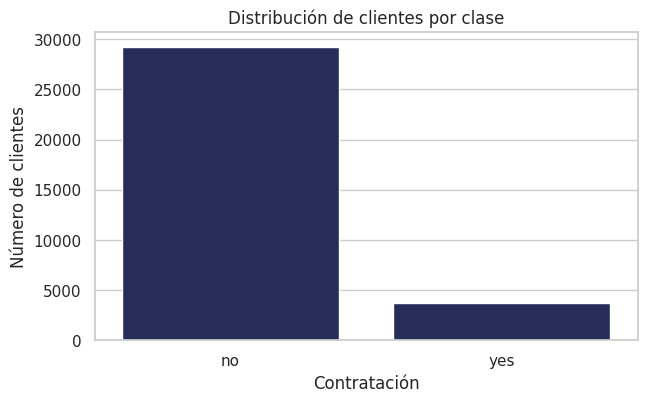

In [104]:
# D1. Escribe el código que muestre:
#  - el número y el porcentaje de clientes de cada clase en ent,
conteo = ent["y"].value_counts()
porcentaje = ent["y"].value_counts(normalize=True) * 100

resumen = pd.DataFrame({
    "Número de clientes": conteo,
    "Porcentaje (%)": porcentaje
})
print("Distribución de la variable objetivo:")
display(resumen.round(2))

#  - la razón entre la clase mayoritaria y la minoritaria,
razon = conteo.max() / conteo.min()
print(f"Razón mayoritaria/minoritaria: {razon:.2f}:1")

#  - la exactitud de responder siempre "no",
exactitud_no = (ent["y"] == "no").mean() * 100
print(f'Exactitud prediciendo siempre "no": {exactitud_no:.2f}%')

#  - una gráfica de barras con el número de clientes por clase.
plt.figure(figsize=(7, 4))
orden = ["no", "yes"]

ax = sns.countplot(
    data=ent,
    x="y",
    order=orden,
    color="#1E2761"
)

ax.set_title("Distribución de clientes por clase")
ax.set_xlabel("Contratación")
ax.set_ylabel("Número de clientes")

**Tu observación.** Compara con tu predicción de las partes A y D y explica qué implica para la evaluación del modelo. Escribe tu respuesta aquí y compárala con tu predicción.

Considero que la variable objetivo está desbalanceada, ya que hay más clientes que no contratan el producto (no) que clientes que sí lo contratan (yes). Por ello, un modelo que siempre prediga no puede obtener una exactitud relativamente alta, equivalente al porcentaje de clientes de esa clase.

Esto implica que la exactitud (accuracy) no es suficiente para evaluar el modelo, porque puede dar una impresión engañosa de su rendimiento. También es necesario analizar la precisión (precision), la sensibilidad (recall) y la medida F1, especialmente para la clase yes.

### D2. Variables numéricas según la clase

**Por qué.** Para cada característica numérica interesa cómo se distribuye en cada clase: si lo hace de forma distinta, la variable separa a quienes contratan de quienes no. Se compara la mediana porque es resistente a valores extremos.

**Tu predicción.** ¿Cuáles de las variables numéricas esperas que más difieran entre quienes contratan y quienes no? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

Mediana de las variables numéricas por clase de y:


,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
y,,,,,,,,,,
no,38.0,164.0,2.0,999.0,0.0,1.1,93.918,-41.8,4.857,5195.8
yes,37.0,448.0,2.0,999.0,0.0,-1.8,93.200,-40.4,1.266,5099.1


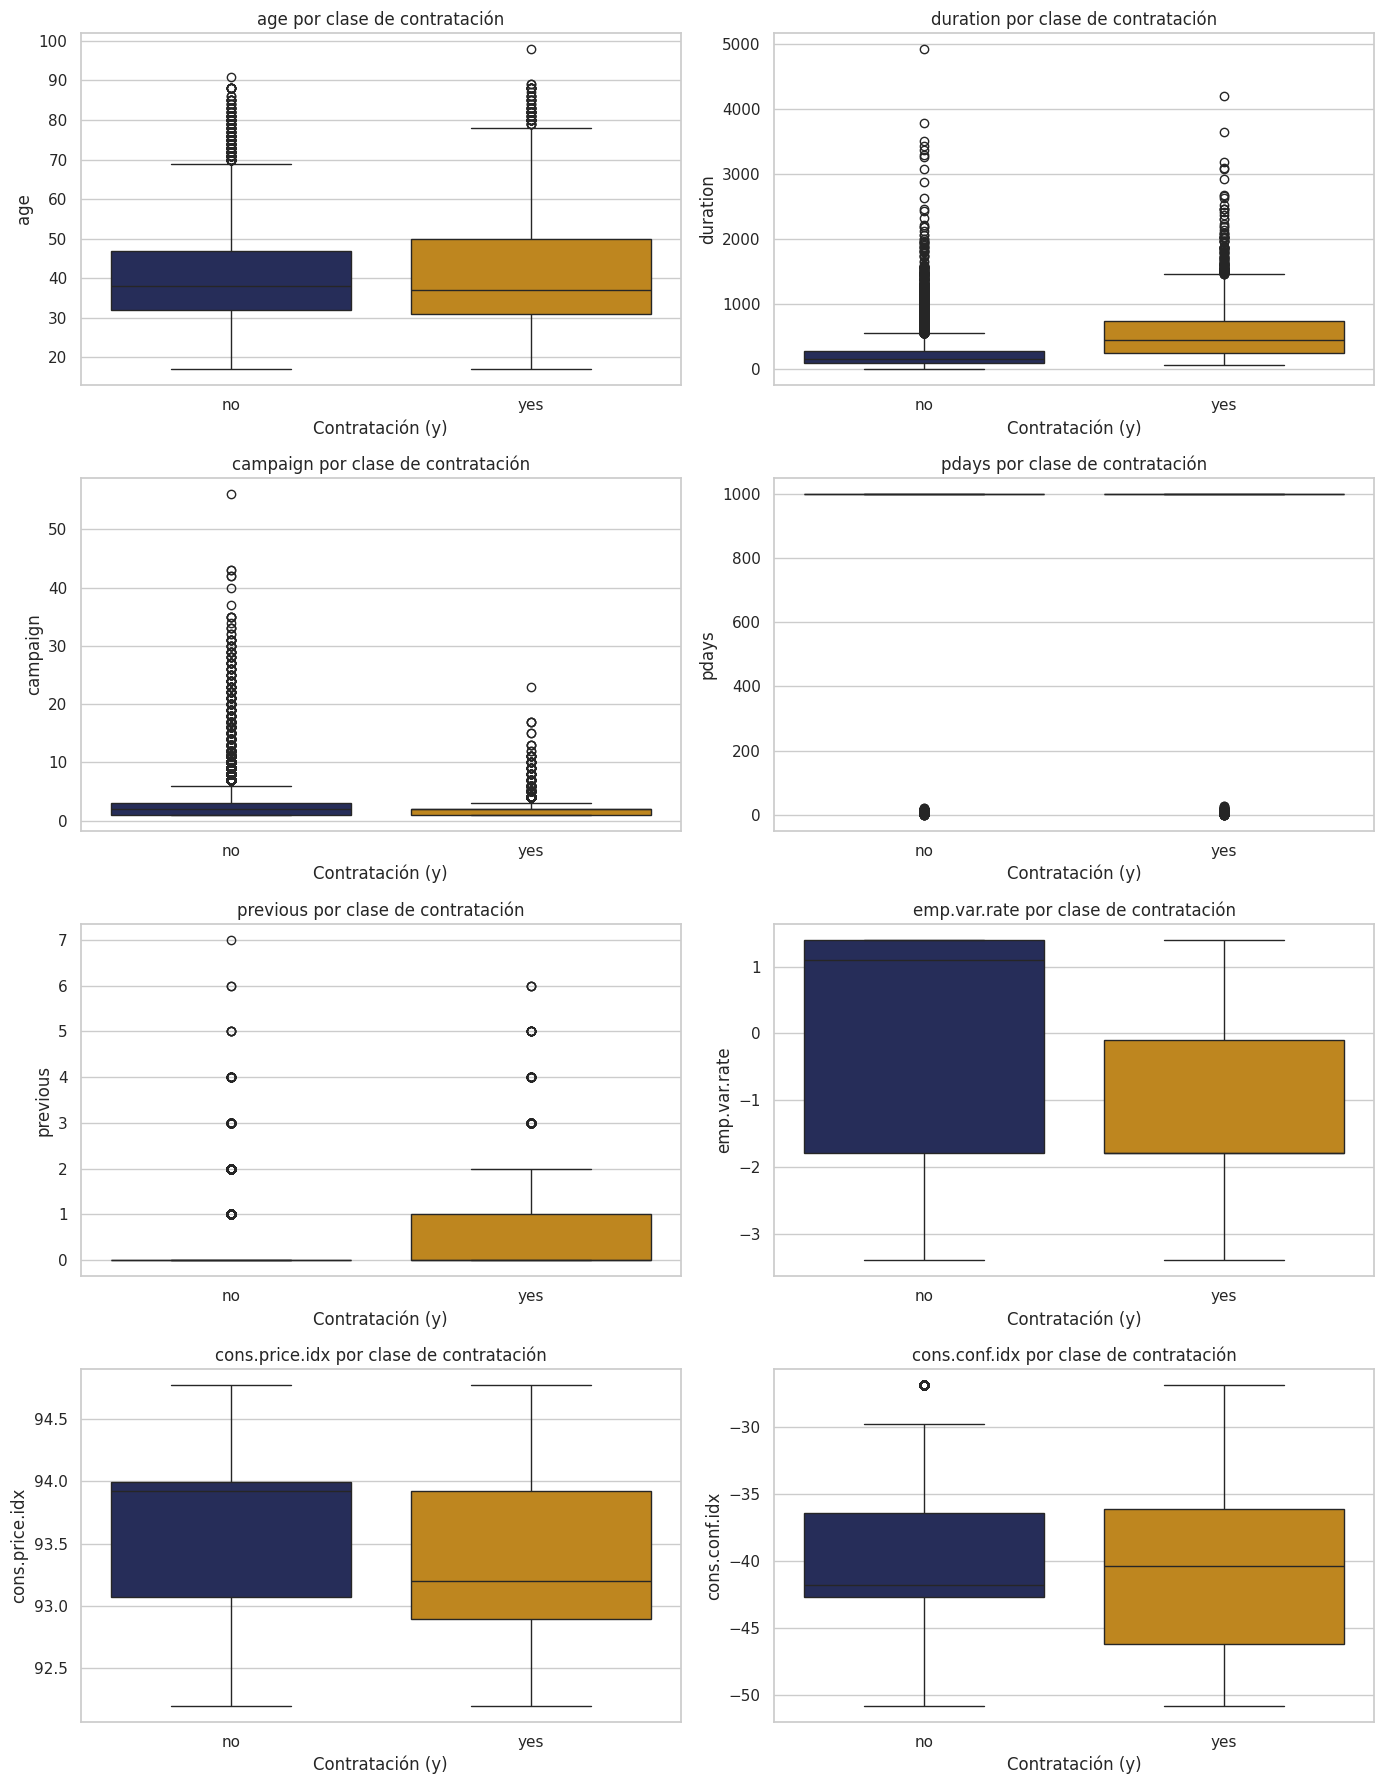

In [105]:
# D2. Escribe el código que muestre:
#  - la mediana de cada variable numérica (lista numericas) por clase de y,
medianas = ent.groupby("y")[numericas].median()

print("Mediana de las variables numéricas por clase de y:")
display(medianas)

#  - diagramas de caja por clase de y de al menos tres variables numéricas que elijas.
variables_graficas = [
    "age", "duration", "campaign", "pdays", "previous",
    "emp.var.rate", "cons.price.idx", "cons.conf.idx"
]

fig, axes = plt.subplots(4, 2, figsize=(14, 18))
axes = axes.flatten()

for ax, variable in zip(axes, variables_graficas):
    sns.boxplot(
        data=ent,
        x="y",
        y=variable,
        hue="y",
        order=["no", "yes"],
        palette=COLORES_CLASE,
        legend=False,
        ax=ax
    )
    ax.set_title(f"{variable} por clase de contratación")
    ax.set_xlabel("Contratación (y)")
    ax.set_ylabel(variable)

plt.tight_layout()
plt.show()

**Tu observación.** Indica qué variables separan las clases y cuáles no, con las medianas. Escribe tu respuesta aquí y compárala con tu predicción.
Las medianas permiten observar diferencias entre los clientes que contrataron el producto (yes) y los que no (no). Espero que variables como duration y algunos indicadores económicos, como emp.var.rate y cons.conf.idx, presenten diferencias entre ambas clases. En cambio, variables como age podrían mostrar medianas similares y tener menor capacidad de separación por sí solas.

### D3. Valores atípicos

**Por qué.** Los modelos lineales, las máquinas de soporte vectorial y las redes neuronales son sensibles a valores extremos y a la escala; los árboles de decisión y sus conjuntos no lo son. El EDA documenta el problema y la decisión depende del modelo.

Los límites de Tukey (1.5 veces el rango intercuartílico) se calculan con los cuartiles de los datos, por lo que se obtienen con el conjunto de entrenamiento.

**Tu predicción.** ¿Qué variables numéricas esperas que tengan más registros fuera de los límites de Tukey? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

Espero que las variables pdays, duration, campaign y previous tengan más registros fuera de los límites de Tukey

In [106]:
# D3. Escribe el código que calcule, con ent, los límites inferior y superior de Tukey
resultados_tukey = []

for variable in numericas:
    Q1 = ent[variable].quantile(0.25)
    Q3 = ent[variable].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    fuera = (
        (ent[variable] < limite_inferior) |
        (ent[variable] > limite_superior)
    ).sum()
    resultados_tukey.append({
        "Variable": variable,
        "Límite inferior": limite_inferior,
        "Límite superior": limite_superior,
        "Registros fuera de límites": fuera
    })

# de cada variable de la lista numericas y muestre cuántos registros quedan fuera de ellos por variable.
tabla_tukey = pd.DataFrame(resultados_tukey)
display(tabla_tukey.round(2))

,Variable,Límite inferior,Límite superior,Registros fuera de límites
0,age,9.50,69.50,368
1,duration,-221.00,643.00,2366
2,campaign,-2.00,6.00,1916
3,pdays,999.00,999.00,1226
4,previous,0.00,0.00,4534
5,emp.var.rate,-6.60,6.20,0
6,cons.price.idx,91.70,95.37,0
7,cons.conf.idx,-52.15,-26.95,359
8,euribor3m,-4.08,10.39,0
9,nr.employed,4905.60,5421.60,0


**Tu respuesta.** ¿Eliminarías los registros atípicos de alguna variable? Justifica por variable con lo que sabes de su significado. Escribe tu respuesta aquí.

No eliminaría automáticamente los registros atípicos, porque los límites de Tukey identifican valores extremos, pero no necesariamente errores. Decidiría el tratamiento según el significado de cada variable:

age: no eliminaría los valores atípicos sin comprobar primero si las edades son plausibles. Una edad elevada puede corresponder a un cliente real.

duration: conservaría las duraciones extremas, ya que algunas llamadas pueden ser legítimamente mucho más largas que otras.

campaign: mantendría los valores altos si representan el número real de contactos realizados durante la campaña. Revisaría únicamente los valores imposibles o erróneos.

### D4. Asimetría y re-expresión

**Por qué.** Cuando una variable tiene asimetría fuerte, una transformación monótona (raíz cuadrada o logaritmo) puede acercar su distribución a una forma simétrica. Un modelo sensible a la escala se beneficia; uno basado en árboles no. La asimetría guía la decisión.

**Tu predicción.** ¿Cuál transformación, raíz cuadrada o logaritmo (`np.log1p`), reducirá más la asimetría de `campaign`? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

Comparación de la asimetría:


,Asimetría original,Asimetría raíz cuadrada,Asimetría log1p
Variable,,,
age,0.761,0.426,0.132
duration,3.327,1.204,-0.430
campaign,4.743,2.163,1.351


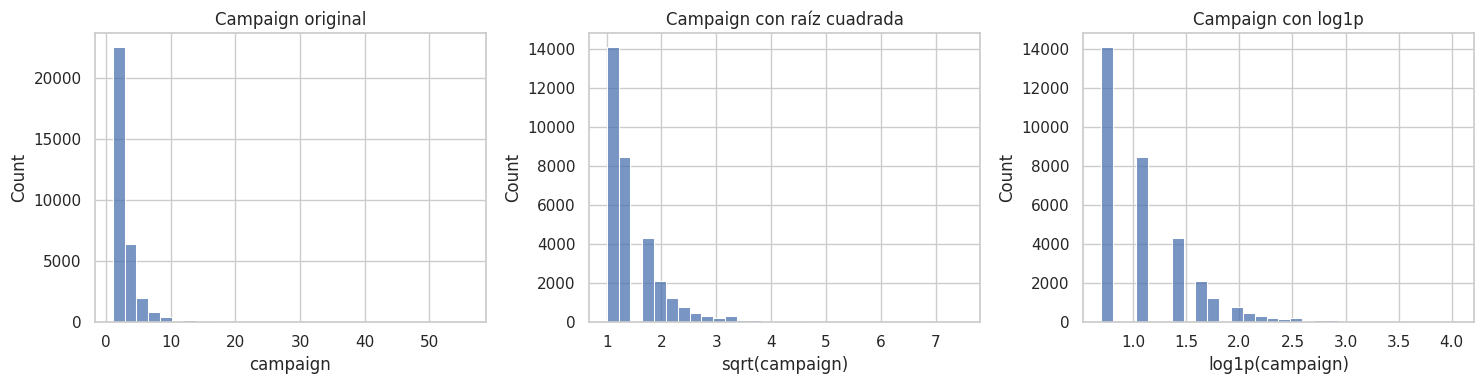

In [107]:
# D4. Escribe el código que muestre una tabla con la asimetría original, con raíz cuadrada y con
# logaritmo (np.log1p) de las variables age, duration y campaign, calculada con ent.
variables = ["age", "duration", "campaign"]

# 1. Calcular la asimetría original y transformada
resultados = []

for variable in variables:
    serie = ent[variable].dropna()

    resultados.append({
        "Variable": variable,
        "Asimetría original": serie.skew(),
        "Asimetría raíz cuadrada": np.sqrt(serie).skew(),
        "Asimetría log1p": np.log1p(serie).skew()
    })

tabla_asimetria = pd.DataFrame(resultados).set_index("Variable")
print("Comparación de la asimetría:")
display(tabla_asimetria.round(3))

# Después grafica los histogramas de campaign: original y transformada.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(ent["campaign"].dropna(), bins=30, ax=axes[0])
axes[0].set_title("Campaign original")
axes[0].set_xlabel("campaign")

sns.histplot(np.sqrt(ent["campaign"].dropna()), bins=30, ax=axes[1])
axes[1].set_title("Campaign con raíz cuadrada")
axes[1].set_xlabel("sqrt(campaign)")

sns.histplot(np.log1p(ent["campaign"].dropna()), bins=30, ax=axes[2])
axes[2].set_title("Campaign con log1p")
axes[2].set_xlabel("log1p(campaign)")

plt.tight_layout()
plt.show()

**Tu observación.** Reporta las asimetrías y decide qué transformación, si alguna, aplicarías a cada variable. Escribe tu respuesta aquí y compárala con tu predicción.
age: mantendría la variable original si su asimetría es cercana a cero. Si presenta una asimetría positiva marcada, consideraría la raíz cuadrada o np.log1p, según cuál la reduzca más.

duration: consideraría aplicar np.log1p, porque las duraciones de las llamadas suelen presentar asimetría positiva y algunos valores elevados.

campaign: consideraría np.log1p, ya que el número de contactos suele concentrarse en valores pequeños y tener una cola hacia la derecha.

## Parte E. Exploración de las variables categóricas, entrenamiento

**Por qué.** Para una característica categórica, la medida natural es la **tasa de contratación por categoría** comparada con la tasa global, junto con el número de clientes: una tasa calculada con pocos registros es poco confiable.

**Tu predicción.** ¿Qué variable categórica esperas que tenga las categorías con mayor tasa de contratación? ¿Y cuáles esperas que casi no separen las clases? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

 La variable categórica poutcome tenga categorías con tasas de contratación diferentes, especialmente que la categoría success presente una tasa de contratación más alta, porque indica que la campaña de marketing anterior tuvo éxito

In [108]:
# E1. Escribe el código que muestre:
#  - el número de categorías de cada variable de la lista categoricas,
print("Número de categorías por variable:")

num_categorias = ent[categoricas].nunique(dropna=False).sort_values(
    ascending=False
)

display(num_categorias.to_frame(name="Número de categorías"))
#  - la tasa global de contratación en ent.
tasa_global = (ent["y"] == "yes").mean() * 100

print(f"Tasa global de contratación en ent: {tasa_global:.2f}%")

Número de categorías por variable:


,Número de categorías
job,12
month,10
education,8
day_of_week,5
marital,4
default,3
loan,3
housing,3
poutcome,3
contact,2


Tasa global de contratación en ent: 11.27%


In [109]:
# E2. Escribe el código que construya una tabla con el número de clientes y la tasa de contratación (en %)
# de cada categoría de cada variable de categoricas. Muestra:
df_largo = ent[categoricas + ["y"]].melt(
    id_vars="y",
    value_vars=categoricas,
    var_name="variable",
    value_name="categoria"
)
#  - las 12 categorías con mayor tasa,
tabla_tasas = (
    df_largo
    .groupby(["variable", "categoria"], dropna=False)
    .agg(
        clientes=("y", "size"),
        contrataciones=("y", lambda s: (s == "yes").sum()),
        tasa_contratacion=("y", lambda s: (s == "yes").mean() * 100)
    )
    .reset_index()
    .sort_values("tasa_contratacion", ascending=False)
)

# Mostrar la tabla completa
display(tabla_tasas.round({"tasa_contratacion": 2}))

print("12 categorías con mayor tasa de contratación:")
display(
    tabla_tasas.head(12).round({"tasa_contratacion": 2})
)
#  - las 8 con menor tasa,
print("8 categorías con menor tasa de contratación:")
display(
    tabla_tasas.tail(8)
    .sort_values("tasa_contratacion")
    .round({"tasa_contratacion": 2})
)
#  - las tablas de default, housing, loan y day_of_week.
variables_interes = ["default", "housing", "loan", "day_of_week"]

for variable in variables_interes:
    print(f"\nResultados para {variable}:")
    display(
        tabla_tasas[tabla_tasas["variable"] == variable]
        .sort_values("tasa_contratacion", ascending=False)
        .round({"tasa_contratacion": 2})
        .reset_index(drop=True)
    )
# Pista: reutiliza el patrón melt + groupby + agg del notebook guiado del caso Telco.

,variable,categoria,clientes,contrataciones,tasa_contratacion
52,poutcome,success,1105,717,64.89
42,month,dec,143,72,50.35
45,month,mar,436,217,49.77
49,month,sep,464,207,44.61
48,month,oct,587,254,43.27
29,job,student,711,217,30.52
26,job,retired,1366,348,25.48
40,month,apr,2085,427,20.48
14,education,illiterate,16,3,18.75
39,marital,unknown,65,11,16.92


12 categorías con mayor tasa de contratación:


,variable,categoria,clientes,contrataciones,tasa_contratacion
52,poutcome,success,1105,717,64.89
42,month,dec,143,72,50.35
45,month,mar,436,217,49.77
49,month,sep,464,207,44.61
48,month,oct,587,254,43.27
29,job,student,711,217,30.52
26,job,retired,1366,348,25.48
40,month,apr,2085,427,20.48
14,education,illiterate,16,3,18.75
39,marital,unknown,65,11,16.92


8 categorías con menor tasa de contratación:


,variable,categoria,clientes,contrataciones,tasa_contratacion
9,default,yes,3,0,0.00
8,default,unknown,6940,361,5.20
1,contact,telephone,12042,638,5.30
46,month,may,11011,699,6.35
22,job,blue-collar,7441,515,6.92
12,education,basic.9y,4826,369,7.65
28,job,services,3196,254,7.95
11,education,basic.6y,1865,156,8.36


...

,variable,categoria,clientes,contrataciones,tasa_contratacion
0,housing,yes,17254,1994,11.56
1,housing,unknown,796,90,11.31
2,housing,no,14900,1628,10.93



Resultados para loan:


,variable,categoria,clientes,contrataciones,tasa_contratacion
0,loan,unknown,796,90,11.31
1,loan,no,27131,3058,11.27
2,loan,yes,5023,564,11.23



Resultados para day_of_week:


,variable,categoria,clientes,contrataciones,tasa_contratacion
0,day_of_week,thu,6857,823,12.00
1,day_of_week,tue,6444,748,11.61
2,day_of_week,wed,6515,753,11.56
3,day_of_week,fri,6322,690,10.91
4,day_of_week,mon,6812,698,10.25


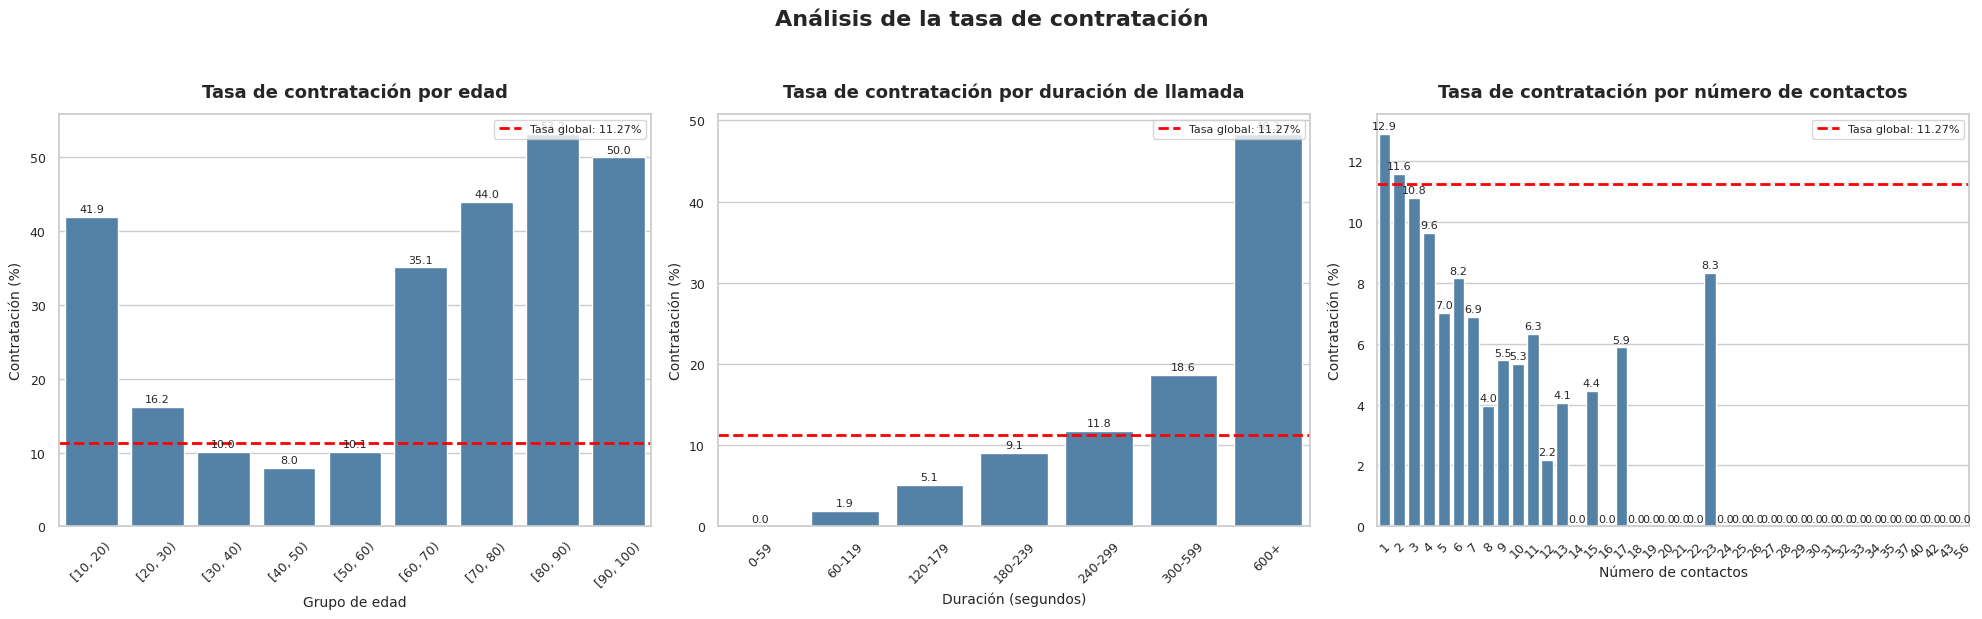

In [110]:
# E3. Escribe el código que grafique la tasa de contratación por categoría de month (en orden
# cronológico: mar, apr, may, jun, jul, aug, sep, oct, nov, dec), poutcome y contact,
sns.set_theme(style="whitegrid", context="notebook")

# Tasa global de contratación
tasa_global = (ent["y"] == "yes").mean() * 100

# Copia de los datos
df = ent.copy()

# Agrupar edad en intervalos de 10 años
df["age_group"] = pd.cut(
    df["age"],
    bins=range(0, 101, 10),
    right=False
)

# Agrupar duración de llamada en intervalos de 60 segundos
df["duration_group"] = pd.cut(
    df["duration"],
    bins=[0, 60, 120, 180, 240, 300, 600, float("inf")],
    labels=[
        "0-59", "60-119", "120-179", "180-239",
        "240-299", "300-599", "600+"
    ],
    right=False
)

# Variables y títulos
variables = ["age_group", "duration_group", "campaign"]
titulos = [
    "Tasa de contratación por edad",
    "Tasa de contratación por duración de llamada",
    "Tasa de contratación por número de contactos"
]

# Crear gráficos
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, variable, titulo in zip(axes, variables, titulos):

    # Tasa de contratación por categoría
    tasas = (
        df.groupby(variable, observed=False)["y"]
        .apply(lambda s: (s == "yes").mean() * 100)
        .dropna()
    )

    # Ordenar categorías numéricas por tasa, excepto los intervalos
    if variable == "campaign":
        tasas = tasas.sort_index()

    # Graficar
    sns.barplot(
        x=[str(x) for x in tasas.index],
        y=tasas.values,
        ax=ax,
        color="steelblue",
        edgecolor="white"
    )

    # Línea de referencia global
    ax.axhline(
        tasa_global,
        color="red",
        linestyle="--",
        linewidth=2,
        label=f"Tasa global: {tasa_global:.2f}%"
    )

    # Formato
    ax.set_title(titulo, fontsize=13, fontweight="bold", pad=12)
    ax.set_xlabel(
        "Grupo de edad" if variable == "age_group"
        else "Duración (segundos)" if variable == "duration_group"
        else "Número de contactos",
        fontsize=10
    )
    ax.set_ylabel("Contratación (%)", fontsize=10)
    ax.tick_params(axis="x", labelsize=9, rotation=45)
    ax.tick_params(axis="y", labelsize=9)
    ax.legend(fontsize=8, loc="upper right")
    ax.set_ylim(bottom=0)

    # Porcentajes encima de las barras
    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.1f",
            fontsize=8,
            padding=2
        )

plt.suptitle(
    "Análisis de la tasa de contratación",
    fontsize=16,
    fontweight="bold",
    y=1.03
)

plt.tight_layout()
plt.show()

**Tu observación.** Identifica las categorías con mayor y menor tasa, con su tasa y su número de clientes, y las variables que casi no separan las clases. Escribe tu respuesta aquí y compárala con tu predicción.

campaign: parece tener una capacidad de separación limitada en las categorías más frecuentes. La tasa del primer contacto es del 12.9 %, relativamente cercana al promedio global del 11.27 %. Las tasas de 0 % en categorías con muchos contactos podrían deberse a que hay muy pocos clientes en ellas.

age: muestra diferencias entre grupos, pero las tasas extremas de edades avanzadas podrían ser poco fiables si hay pocos clientes en esos intervalos.

duration: presenta una separación aparente muy marcada. La tasa aumenta con la duración de la llamada, desde 0 % para llamadas de menos de un minuto hasta aproximadamente 48 % para llamadas de 600 segundos o más.

**Tu respuesta.** En `default`, ¿qué indica que la categoría `unknown` tenga una tasa de contratación distinta a la de `no`? ¿Qué hay que cuidar con las categorías `yes` de `default` o `illiterate` de `education`? Escribe tu respuesta aquí.
Las categorías poco frecuentes pueden mostrar tasas llamativas, pero su fiabilidad depende del tamaño de la muestra. Además, unknown puede aportar información sobre la ausencia de datos, por lo que no debe tratarse automáticamente como una categoría equivalente a no.

## Parte F. Relaciones entre características y variable `duration`, entrenamiento

### F1. Relaciones entre características

**Por qué.** Dos características muy relacionadas son redundantes y pueden causar inestabilidad en modelos lineales (colinealidad).

**Tu predicción.** ¿Qué pares de indicadores económicos (lista `macro`) esperas que estén más correlacionados? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

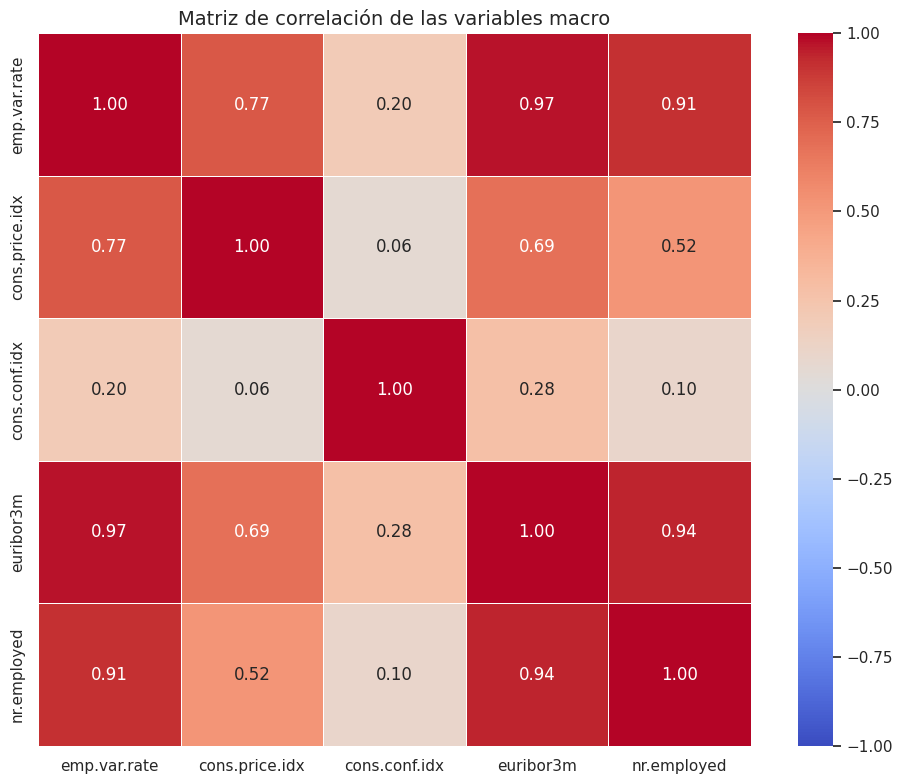

In [111]:
# F1. Escribe el código que muestre un mapa de calor con la matriz de correlación de las variables de la lista macro,
# calculada con ent, con los valores anotados en cada celda.
matriz_corr = ent[macro].corr()

# Crear el mapa de calor
plt.figure(figsize=(10, 8))

sns.heatmap(
    matriz_corr,
    annot=True,          # Mostrar los valores en cada celda
    fmt=".2f",           # Dos decimales
    cmap="coolwarm",     # Colores para correlaciones positivas y negativas
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    square=True
)

plt.title("Matriz de correlación de las variables macro", fontsize=14)
plt.tight_layout()
plt.show()

**Tu observación.** Reporta los pares más correlacionados y la decisión que implican. Escribe tu respuesta aquí y compárala con tu predicción.

Multicolinealidad elevada: las variables emp.var.rate, euribor3m y nr.employed presentan correlaciones muy altas entre sí. En un modelo de regresión logística, esto puede dificultar la interpretación de los coeficientes y aumentar su inestabilidad.

Selección de variables: probaría inicialmente un modelo con euribor3m y otro con emp.var.rate o nr.employed, comparando su rendimiento mediante validación cruzada. No eliminaría variables sin evaluar su utilidad predictiva.

cons.conf.idx: sus correlaciones con las demás variables son bajas (entre 0.06 y 0.28). Conviene conservarla inicialmente, pues podría aportar información complementaria.

### F2. La variable `duration`

**Por qué.** Una variable puede tener una relación muy fuerte con el objetivo y aun así no ser utilizable. Esto ocurre cuando su valor solo se conoce después del evento que se quiere predecir.


In [112]:
# F2. Escribe el código que muestre el resumen estadístico (describe) de duration por clase de y.
ent.groupby("y")["duration"].describe()

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,29238.0,221.148198,208.303557,0.0,95.0,164.0,279.0,4918.0
yes,3712.0,549.398976,397.490060,63.0,252.0,448.0,737.0,4199.0


**Tu respuesta.** ¿Incluirías `duration` como característica de un modelo que se usará para decidir a quién llamar? Justifica con la definición de la variable y con lo observado. Escribe tu respuesta aquí.


duration representa la duración de la última llamada al cliente, medida en segundos. Por tanto, solo se conoce una vez que la llamada ha ocurrido.

Lo observado: el análisis mostró que la tasa de contratación aumenta considerablemente con la duración de la llamada. Por ejemplo, las llamadas de menos de 60 segundos presentan una tasa de contratación del 0 %, mientras que las de 600 segundos o más alcanzan aproximadamente el 48 %.

Problema de fuga de información (data leakage): aunque duration parece ser muy predictiva, no está disponible antes de realizar la llamada. Incluirla produciría un modelo que utiliza información futura respecto al momento de la decisión.

Conclusión: excluiría duration del modelo de selección de clientes y utilizaría variables disponibles antes de llamar, como age, job, education o las variables macroeconómicas. La duración podría utilizarse en un análisis posterior para estudiar los resultados de las llamadas, pero no para decidir a quién contactar inicialmente.

**Tu respuesta.** El conjunto está ordenado por fecha y los indicadores económicos varían con el tiempo. ¿Qué implica dividir al azar, como en la parte C, para un modelo que se usará en campañas futuras? Escribe tu respuesta aquí.Los datos al azar puede provocar una estimación demasiado optimista del rendimiento del modelo, porque mezcla observaciones de periodos anteriores y posteriores tanto en entrenamiento como en prueba. Como los indicadores económicos varían con el tiempo, el modelo podría aprovechar patrones de periodos futuros que no estarían disponibles al realizar campañas reales.

## Parte G. Hoja de decisiones y justificación del uso de los datos

### G1. Hoja de decisiones

**Por qué.** El producto de un EDA predictivo es una lista de decisiones, cada una con su evidencia. Ninguna decisión se aplica todavía sobre los datos.

Completa la tabla con **al menos siete decisiones**, cada una con un hallazgo de tu análisis (con su cifra), la decisión y el tema del curso donde se aplicaría (preprocesamiento, modelos, evaluación). Debe aparecer al menos una decisión sobre cada uno de estos aspectos: variable no utilizable, valores faltantes o códigos especiales, desbalance de clases, redundancia entre características y asimetría.

Edita esta celda y agrega las filas que necesites.

duration muestra una tasa de contratación aproximada del 0 % para llamadas de menos de 60 segundos y del 48 % para llamadas de 600 segundos o más. Sin embargo, solo se conoce después de realizar la llamada.

Excluir duration del modelo que decidirá a quién llamar para evitar fuga de información (data leakage).

Preprocesamiento / Modelos

2

La matriz de correlación muestra
r
=
0.97
r=0.97 entre emp.var.rate y euribor3m.

Evaluar la redundancia y comparar modelos que utilicen una sola de estas variables para reducir posibles problemas de multicolinealidad.

Preprocesamiento / Modelos

3

euribor3m y nr.employed presentan una correlación de
r
=
0.94
r=0.94; emp.var.rate y nr.employed, de
r
=
0.91
r=0.91.

Revisar conjuntamente estas tres variables y evaluar cuáles aportan información adicional al modelo.

Preprocesamiento / Modelos

4

La tasa global de contratación observada es del 11.27 %, frente al 88.73 % de clientes que no contrataron.

Evaluar métricas adecuadas para clases desbalanceadas, como precision, recall, F1 y PR-AUC, en lugar de utilizar únicamente accuracy.

Evaluación

5

En age, el grupo de 80–90 años presenta una tasa aproximada del 52–53 %, mientras que el grupo de 40–50 años presenta un 8 %.

Revisar el número de clientes por intervalo antes de interpretar las tasas extremas y considerar agrupar categorías con pocas observaciones.

Preprocesamiento / Evaluación

6

En campaign, el primer contacto presenta una tasa de contratación del 12.9 %, mientras que algunas categorías con más contactos presentan tasas del 0 %.

Comprobar el tamaño de muestra de cada categoría y evitar conclusiones basadas en grupos con muy pocos clientes.

Preprocesamiento / Evaluación

7

La variable duration presenta una distribución muy desigual de las tasas de contratación según los intervalos de duración; los intervalos largos muestran tasas superiores.

Examinar la asimetría de duration y, si se utiliza en análisis posteriores a la llamada, evaluar transformaciones o agrupaciones. Mantenerla excluida del modelo de selección previo al contacto.


| Hallazgo (con cifra) | Decisión | Se aplica en |
|duration presenta una tasa de contratación aproximada de 0 % para llamadas menores de 60 segundos y de 48 % para llamadas de 600 segundos o más.|Excluir duration para evitar fuga de información, porque solo se conoce después de llamar.|emp.var.rate y euribor3m tienen una correlación de 0.97.|
| Evaluar si conviene conservar solo una de las variables para reducir la multicolinealidad.|La tasa global de contratación es 11.27 %, frente al 88.73 % de no contratación.

En age, el grupo de 80–90 años presenta una tasa aproximada del 52–53 %, mientras que el de 40–50 años presenta un 8 %.

En default, la categoría unknown presenta una tasa de contratación distinta de no.

### G2. Uso de los datos

**Tu respuesta.** En esta actividad, ¿qué partes se hicieron con el conjunto total y cuáles solo con entrenamiento? Explica el criterio. Escribe tu respuesta aquí.

El cálculo de estadísticas descriptivas, las tasas de contratación, la detección de valores faltantes y el análisis de correlaciones, se realizó con el conjunto total ent para comprender los datos y formular decisiones. En cambio, las operaciones que aprenden parámetros de los datos, como la imputación de valores faltantes, la estandarización, la selección de características y el entrenamiento del modelo, deben ajustarse únicamente con el conjunto de entrenamiento. Después, esos mismos parámetros se aplican al conjunto de prueba, sin volver a ajustarlos. El criterio es evitar la fuga de información (data leakage) y obtener una evaluación realista del rendimiento del modelo con datos nuevos.

**Tu respuesta.** Si hubieras explorado también el conjunto de prueba, ¿qué decisión de tu hoja podría quedar sesgada y cómo se reflejaría en la evaluación final? Escribe tu respuesta aquí.

Una decisión que podría quedar sesgada es la selección de variables macroeconómicas, ya que se observó una correlación de 0.97 entre emp.var.rate y euribor3m. Si hubiera utilizado el conjunto de prueba para decidir qué variables conservar o ajustar el modelo, habría incorporado información que debería reservarse para la evaluación final. Esto podría provocar una estimación demasiado optimista del rendimiento, porque el modelo estaría indirectamente adaptado a los datos de prueba.